In [1]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms, models
from tqdm import tqdm, trange
import numpy as np
from utils import save_checkpoint, load_checkpoint, train_func_classification
import matplotlib.pyplot as plt
import pathlib
import random

d:\anaconda3\envs\CS2109S\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
from torch_influence.base import BaseObjective
from torch_influence.modules import CGInfluenceModule, LiSSAInfluenceModule, AutogradInfluenceModule

In [3]:
transform = transforms.Compose([transforms.Resize((299, 299)), transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cifar10_train = datasets.CIFAR10('../data', train=True, download=True, transform=transform)
cifar10_test = datasets.CIFAR10('../data', train=False, download=True, transform=transform)
cifar10_train_loader = DataLoader(cifar10_train, batch_size=20, shuffle=True)
cifar10_test_loader = DataLoader(cifar10_test, batch_size=20, shuffle=True)

Files already downloaded and verified
Files already downloaded and verified


In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DOGFISH_RAW_PATH = '../data/dogfish/dataset_dog-fish_train-900_test-300.npz'
DOGFISH_EMB_PATH = '../data/dogfish/dataset_dog-fish_embeds.npz'
dogfish_raw = np.load(DOGFISH_RAW_PATH, mmap_mode='r')

class DogfishDataset(Dataset):
    def __init__(self, X, Y, transforms=None):
        self.X = X
        self.Y = Y
        self.transforms = transforms
        
    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        sample = self.X[idx]
        label = torch.tensor([self.Y[idx]])
        if self.transforms:
            sample = self.transforms(sample)
        return sample, label

# split: train or validation
def load_dogfish_examples(split, idxs):
    image = dogfish_raw[f"X_{split}"][idxs]
    label = dogfish_raw[f"Y_{split}"][idxs]
    return image, label

def dataloader_from_npz(path, type):
    data = np.load(path, "r")
    print(data)
    transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x.permute([2, 0, 1]))]) if type == "raw" else None
    train = DataLoader(DogfishDataset(data["X_train"], data["Y_train"], transforms=transform), batch_size=20, shuffle=True)
    test = DataLoader(DogfishDataset(data["X_test"], data["Y_test"], transforms=transform), batch_size=20, shuffle=False)
    return train, test

def load_inception_embeds():
    # load pretrained Inceptionv3
    if not pathlib.Path(DOGFISH_EMB_PATH).is_file():
        model = models.inception_v3(pretrained=True, transform_input=False)
        model.fc = nn.Identity()  # remove the last layer
        model.eval()
        model = model.to(DEVICE)

        embeds = {}
        raws = {}
        for split in ("train", "test"):
            n = 2 * (900 if (split == "train") else 300)

            X_embed, Y_embed = [], []
            X_raw, Y_raw = [], []
            for idx in trange(0, n, 20, desc=f"Embedding Dogfish ({split})"):
                batch_idxs = [idx + offset for offset in range(20)]
                images, labels = load_dogfish_examples(split, batch_idxs)
                images = torch.tensor(images, dtype=torch.float32, device=DEVICE)
                images = images.permute([0, 3, 1, 2]) # move channel to the second dimension
                X_raw.append(images)
                Y_raw.append(labels)
                
                # getting Inceptionv3 embedding
                with torch.no_grad():
                    h = model(images).cpu().numpy()

                X_embed.append(h)
                Y_embed.append(labels)

            embeds[f"X_{split}"] = np.concatenate(X_embed, axis=0).astype(np.float32)
            embeds[f"Y_{split}"] = np.concatenate(Y_embed, axis=0).astype(np.float32)
        
        np.savez(DOGFISH_EMB_PATH, **embeds)
    print("Loading Dogfish embeddings")
    raw_train, raw_test = dataloader_from_npz(DOGFISH_RAW_PATH, "raw")
    embeds_train, embeds_test = dataloader_from_npz(DOGFISH_EMB_PATH, "embeds")
    return raw_train, raw_test, embeds_train, embeds_test


In [5]:
raw_train, raw_test, embeds_train, embeds_test = load_inception_embeds()

Loading Dogfish embeddings
NpzFile '../data/dogfish/dataset_dog-fish_train-900_test-300.npz' with keys: X_test, X_train, Y_train, Y_test
NpzFile '../data/dogfish/dataset_dog-fish_embeds.npz' with keys: X_train, Y_train, X_test, Y_test


In [6]:
for x, y in embeds_train:
    print(x.shape, y.shape)
    print(type(x))
    break
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

torch.Size([20, 2048]) torch.Size([20, 1])
<class 'torch.Tensor'>


In [7]:
class V3FC(nn.Module):
    def __init__(self):
        super(V3FC, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(2048, 1),
            nn.Flatten(),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

In [8]:
def train_func_classification(model, criterion, optimizer, train_loader, validation_loader, epochs, record_checkpoints=None, save=True):
    train_losses = []
    accuracies = []
    checkpoints = []
    validation_losses = []
    
    for epoch in range(epochs):
        model.train()
        loss = 0.0
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_pred = model(x_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            loss += loss.item()
            
        loss = loss / len(train_loader)
        train_losses.append(loss)
            
        model.eval()
        correct_count = 0
        validation_loss = 0.0
        for x_val_batch, y_val_batch in validation_loader:
            y_pred = model(x_val_batch)
            loss = criterion(y_pred, y_val_batch)
            validation_loss += loss.item()
            predictions = (y_pred > 0.5).int()
            result = predictions == y_val_batch
            correct_count += result.sum()
        validation_loss = validation_loss / len(validation_loader)
        validation_losses.append(validation_loss)
            
        accuracy = (correct_count / len(validation_loader.dataset)).item()
        accuracies.append(accuracy)
        if save:
            print(f"Epoch: {epoch + 1}, Train Loss: {loss}, accuracy: {accuracy}")
        if save:
            if record_checkpoints:
                if (epoch + 1) in record_checkpoints or (
                    epoch > 1 and accuracies[-1] - accuracies[-2] > 0.1) or (epoch + 1 == 115):
                    checkpoint_f = save_checkpoint(model, optimizer, epoch + 1, epochs, f"../checkpoint/{type(model).__name__}")
                    checkpoints.append(checkpoint_f)
            else:
                if ((epoch + 1) / epochs in [0.2, 0.4, 0.6, 0.8, 1.0]) or (
                    epoch > 1 and accuracies[-1] - accuracies[-2] > 0.1) or (epoch + 1 == 115):
                    checkpoint_f = save_checkpoint(model, optimizer, epoch + 1, epochs, filepath=f"../checkpoint/{type(model).__name__}")
                    checkpoints.append(checkpoint_f)
        
    epochs_range = range(1, epochs + 1)
    train_losses = [loss.detach().numpy() for loss in train_losses]
    if save:
        fig, ax1 = plt.subplots(figsize=(10, 5))
        ax1.plot(epochs_range, train_losses, label='Train Loss')
        ax1.plot(epochs_range, validation_losses, label='Validation Loss')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        
        ax2 = ax1.twinx()
        ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
        ax2.set_ylabel('Accuracy')
        
        plt.title('Loss and Accuracy')
        fig.legend()
        plt.show()
    return model, checkpoints, train_losses, accuracies, validation_losses

Epoch: 1, Train Loss: 0.4813728332519531, accuracy: 0.9166666865348816
Checkpoint at 0.01 saved: ../checkpoint/V3FC/V3FC_epoch_1_0.01.pth
Epoch: 2, Train Loss: 0.34372445940971375, accuracy: 0.9350000023841858
Checkpoint at 0.02 saved: ../checkpoint/V3FC/V3FC_epoch_2_0.02.pth
Epoch: 3, Train Loss: 0.26232409477233887, accuracy: 0.9366666674613953
Checkpoint at 0.03 saved: ../checkpoint/V3FC/V3FC_epoch_3_0.03.pth
Epoch: 4, Train Loss: 0.20765700936317444, accuracy: 0.949999988079071
Epoch: 5, Train Loss: 0.17138566076755524, accuracy: 0.9566666483879089
Checkpoint at 0.05 saved: ../checkpoint/V3FC/V3FC_epoch_5_0.05.pth
Epoch: 6, Train Loss: 0.14572790265083313, accuracy: 0.9599999785423279
Epoch: 7, Train Loss: 0.1258508265018463, accuracy: 0.9616666436195374
Epoch: 8, Train Loss: 0.11039678752422333, accuracy: 0.9633333086967468
Epoch: 9, Train Loss: 0.09818729758262634, accuracy: 0.9683333039283752
Epoch: 10, Train Loss: 0.08801795542240143, accuracy: 0.9666666388511658
Checkpoint at 

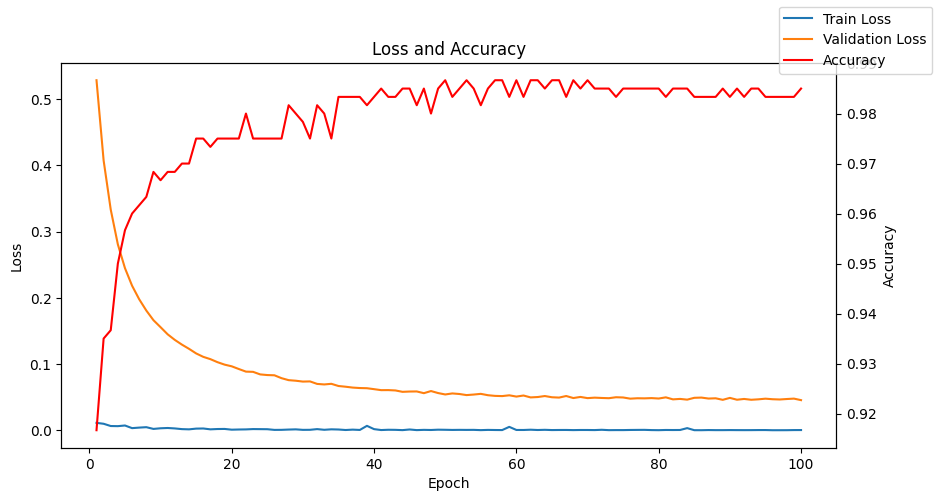

In [290]:
model = V3FC().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
model, checkpoints, train_losses, accuracies, validation_losses = train_func_classification(model, nn.BCELoss(), 
optimizer, embeds_train, embeds_test, 100, record_checkpoints=[1, 2, 3, 5, 10, 15, 20, 40, 60, 80, 100])

In [9]:
checkpoints = ['../checkpoint/V3FC/V3FC_epoch_1_0.01.pth',
 '../checkpoint/V3FC/V3FC_epoch_2_0.02.pth',
 '../checkpoint/V3FC/V3FC_epoch_3_0.03.pth',
 '../checkpoint/V3FC/V3FC_epoch_5_0.05.pth',
 '../checkpoint/V3FC/V3FC_epoch_10_0.1.pth',
 '../checkpoint/V3FC/V3FC_epoch_15_0.15.pth',
 '../checkpoint/V3FC/V3FC_epoch_20_0.2.pth',
 '../checkpoint/V3FC/V3FC_epoch_40_0.4.pth',
 '../checkpoint/V3FC/V3FC_epoch_60_0.6.pth',
 '../checkpoint/V3FC/V3FC_epoch_80_0.8.pth',
 '../checkpoint/V3FC/V3FC_epoch_100_1.0.pth']
checkpoint_labels = np.array([1, 2, 3, 5, 10, 15, 20, 40, 60, 80, 100])

In [10]:
def calculate_influence_score_nn(
    traindata: DataLoader, 
    testdata: DataLoader, 
    model, 
    criterion,
    device,
    epochs=-1,
    train_func=None,
    per_point=-1, 
    appro="cg"
    ):
    """
    Calculate influence score for each training data point
    Parameters
    ----------
    traindata: train data loader
    testdata: test data loader
    model: nn.Module
    per_point: if >= 0: return instance score for specific test point; else return instance score for test sets
    Returns
    -------

    """

    # initialize the model and optimizer
    trainidx = len(traindata.dataset)
    testidx = len(testdata.dataset)

    class NNObjective(BaseObjective):
        
        # batch: Dataset
        def train_outputs(self, model, batch):
            inputs, _ = batch
            inputs = inputs
            inputs = inputs.to(device, dtype=torch.float)
            return model(inputs)

        def train_loss_on_outputs(self, outputs, batch):
            _, labels = batch
            labels = labels
            labels = labels.to(device)
            return criterion(outputs, labels)

        def train_regularization(self, params):
            return 0

        # training loss by default taken to be
        # train_loss_on_outputs + train_regularization

        def test_loss(self, model, params, batch):
            inputs, labels = batch
            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device)
            return criterion(model(inputs), labels)
        
    if train_func != None:
        model, _, val_losses = train_func(
            model = model,
            criterion = criterion,
            optimizer = torch.optim.Adam(model.parameters(), lr=0.0001),
            train_loader = traindata,
            validation_loader = testdata,
            epochs = epochs,
            )
    
    print("Start calculating influence scores...")

    if appro == "lissa":
        print("LissaInfluenceModule")
        module = LiSSAInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            repeat=1,
            depth=2500,
            scale=1e4,
        )
    elif appro == "cg":
        print("CGInfluenceModule")
        module = CGInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            atol=1e-8,
            maxiter=1000,
        )
    elif appro == "autograd":
        print("AutogradInfluenceModule")
        module = AutogradInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003
        )

    print(f"train data size: {len(traindata.dataset)}")
    print(f"test data size: {len(testdata.dataset)}")
    if train_func != None:
        print(f"model performance validation loss / accuracy: {val_losses[-1]}")
    
    if per_point >= 0:
        scores = module.influences(np.arange(trainidx),  np.array([per_point])).cpu().numpy().reshape(-1)
    else:
        scores = module.influences(np.arange(trainidx), np.arange(testidx)).cpu().numpy().reshape(-1)
    return scores

def influence_at_checkpoints(traindata, testdata, model, optimizer,
                             criterion, checkpoints, device, per_point=-1, appro="cg"):
    scores = []
    for checkpoint in tqdm(checkpoints, desc=f"Calculating influence scores"):
        model, optimizer, _, completion_rate = load_checkpoint(model, optimizer, checkpoint)
        print(f"completion_rate: {completion_rate}" )
        score = calculate_influence_score_nn(traindata, testdata, model, criterion, device, per_point=per_point, appro=appro)
        # torch.save(score, f"influence_data/{type(model).__name__}_influence_score_{checkpoint}.pt")
        scores.append(score)
    return scores

In [293]:
model = V3FC().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
dogfish_influences = influence_at_checkpoints(embeds_train, embeds_test, model, optimizer,
                                           nn.BCELoss(), checkpoints, "cpu", appro="lissa")

Calculating influence scores:   0%|          | 0/11 [00:00<?, ?it/s]

Checkpoint loaded at epoch 1 with completion rate 0.01
completion_rate: 0.01
Start calculating influence scores...
LissaInfluenceModule
train data size: 1800
test data size: 600
Calculating stest...


Calculating influence scores:   9%|▉         | 1/11 [00:03<00:39,  3.94s/it]

Checkpoint loaded at epoch 2 with completion rate 0.02
completion_rate: 0.02
Start calculating influence scores...
LissaInfluenceModule
train data size: 1800
test data size: 600
Calculating stest...


Calculating influence scores:  18%|█▊        | 2/11 [00:07<00:35,  3.95s/it]

...

Calculating influence scores:  82%|████████▏ | 9/11 [00:35<00:07,  3.92s/it]

Checkpoint loaded at epoch 80 with completion rate 0.8
completion_rate: 0.8
Start calculating influence scores...
LissaInfluenceModule
train data size: 1800
test data size: 600
Calculating stest...


Calculating influence scores:  91%|█████████ | 10/11 [00:39<00:03,  3.92s/it]

Checkpoint loaded at epoch 100 with completion rate 1.0
completion_rate: 1.0
Start calculating influence scores...
LissaInfluenceModule
train data size: 1800
test data size: 600
Calculating stest...


Calculating influence scores: 100%|██████████| 11/11 [00:43<00:00,  3.92s/it]


In [296]:
torch.save(dogfish_influences, "../influences/dogfish/dogfish_influences.pt")
torch.save(accuracies, "../influences/dogfish/dogfish_accuracies.pt")
torch.save(train_losses, "../influences/dogfish/dogfish_train_losses.pt")
torch.save(validation_losses, "../influences/dogfish/dogfish_validation_losses.pt")

In [11]:
dogfish_influences = torch.load("../influences/dogfish/dogfish_influences.pt")
accuracies = torch.load("../influences/dogfish/dogfish_accuracies.pt")
train_losses = torch.load("../influences/dogfish/dogfish_train_losses.pt")
validation_losses = torch.load("../influences/dogfish/dogfish_validation_losses.pt")

In [13]:
embeds_data = np.load(DOGFISH_EMB_PATH, "r")
transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x.permute([2, 0, 1]))]) if type == "raw" else None
embeds_train_dataset = DogfishDataset(embeds_data["X_train"], embeds_data["Y_train"], transforms=transform)
x_vals = list(range(1, 101))
def top_last_influences(ckpt_influences, train_dataset, num_per_row=10, descending=True):
    ckpts_embeds = []
    
    for influences in ckpt_influences:
        ckpt_embeds = []
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [train_dataset[index] for index in top_indexes]
        for i, (embeds, label) in enumerate(top_influential_train_data):
            ckpt_embeds.append((embeds, label))
        ckpts_embeds.append(ckpt_embeds)
    return ckpts_embeds

    
# Select top 1% influential data points (≈20)
print(len(embeds_train_dataset))
top_ckpts_embeds = top_last_influences(dogfish_influences, embeds_train_dataset, 18)

1800


In [36]:
# Validate Influence Function
def random_idx(checkpoint_influences, dataset, num_data, p):
    checkpoints_indices = []
    for _ in checkpoint_influences:
        num_select = int(p * num_data)
        indices = list(np.arange(len(dataset)))
        random_indices = random.sample(indices, num_select)
        checkpoints_indices.append(random_indices)
    return checkpoints_indices

p = 0.05
num_data = len(embeds_train_dataset)
random_indices = random_idx(dogfish_influences, embeds_train_dataset, num_data, 1 - p)

def validate_influence(influences, train_dataset, test_dataloader, model_class, criterion, device, checkpoints, checkpoint_labels, p):
    # top_ckpts_embeds = top_last_influences(influences, train_dataset, int(p*num_data))
    validate_accuracies = []
    validate_train_losses = []
    validate_validation_losses = []
    rand_validate_accuracies = []
    rand_validate_train_losses = []
    rand_validate_validation_losses = []
    
    for i in tqdm(range(len(checkpoints)), desc=f"Validating influences"):
        sorted_influences = torch.argsort(torch.from_numpy(influences[i]), descending=True)
        top_indexes = sorted_influences[:int(p*num_data)]
        filtered_indices = [i for i in list(range(len(train_dataset))) if i not in top_indexes]
        residual_train_dataset = Subset(train_dataset, filtered_indices)
        residual_dataloader = DataLoader(residual_train_dataset, batch_size=20, shuffle=True)
        
        random_dataset = Subset(train_dataset, random_indices[i])
        random_dataloader = DataLoader(random_dataset, batch_size=64, shuffle=True)
        
        optimizer = torch.optim.Adam(model_class().parameters(), lr=0.0001)
        epochs = checkpoint_labels[i]
        model = model_class().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
        _, _, val_train_losses, val_accuracies, val_validation_losses = train_func_classification(
            model, criterion, optimizer, residual_dataloader, test_dataloader, epochs, save=False)
        model = model_class().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
        _, _, rand_train_losses, rand_accuracies, rand_validation_losses = train_func_classification(
            model, criterion, optimizer, random_dataloader, test_dataloader, epochs, save=False)
        
        validate_train_losses.append(val_train_losses)
        validate_accuracies.append(val_accuracies)
        validate_validation_losses.append(val_validation_losses)
        rand_validate_validation_losses.append(rand_validation_losses)
        rand_validate_accuracies.append(rand_accuracies)
        rand_validate_train_losses.append(rand_train_losses)
    return validate_train_losses, validate_accuracies, validate_validation_losses, rand_validate_train_losses, rand_validate_accuracies, rand_validate_validation_losses

validate_train_losses, validate_accuracies, validate_validation_losses, rand_validate_train_losses, rand_validate_accuracies, rand_validate_validation_losses = validate_influence(dogfish_influences, embeds_train_dataset, embeds_test, V3FC, nn.BCELoss(), device, checkpoints, checkpoint_labels, p)

Validating influences:   0%|          | 0/11 [00:00<?, ?it/s]

Validating influences: 100%|██████████| 11/11 [00:53<00:00,  4.85s/it]


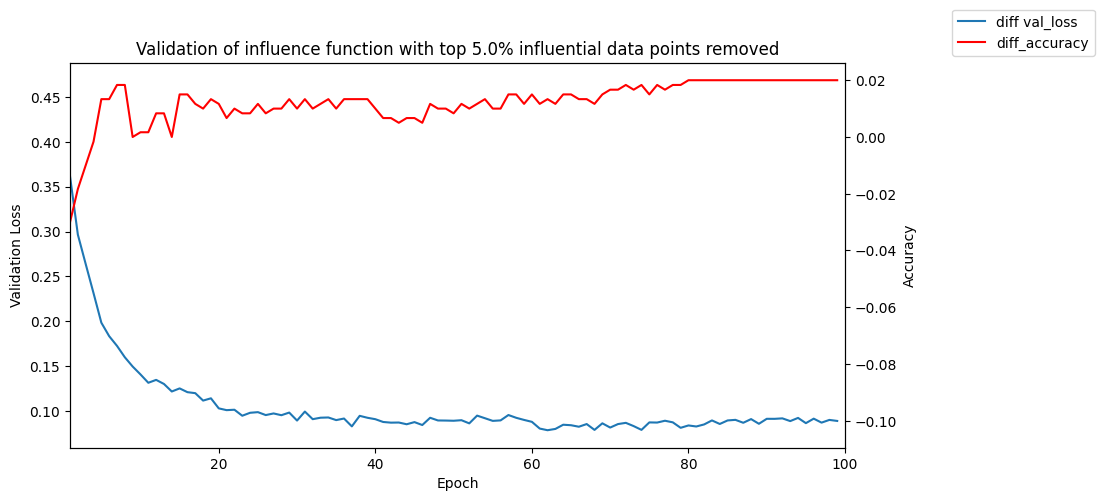

In [37]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
def concat_ckpt_metrics(metrics, ckpt_labels):
    integrate_metrics = []
    for i, metric in enumerate(metrics):
        prev_ckpt = ckpt_labels[i-1] if i > 0 else 0
        integrate_metrics.append(metric[prev_ckpt:])
    return np.concatenate(integrate_metrics)

diff_val_loss = concat_ckpt_metrics(validate_validation_losses, checkpoint_labels) - concat_ckpt_metrics(rand_validate_train_losses, checkpoint_labels) # suppose positive
diff_accuracy = concat_ckpt_metrics(rand_validate_accuracies, checkpoint_labels) - concat_ckpt_metrics(validate_accuracies, checkpoint_labels) # suppose positive

ax1.plot(diff_val_loss, label='diff val_loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(diff_accuracy, label='diff_accuracy', color='r')
ax2.set_ylabel('Accuracy')
plt.title(f'Validation of influence function with top {p*100}% influential data points removed')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

In [32]:
# representiveness
from sklearn.metrics.pairwise import euclidean_distances

def calc_inter_dist(embeds):
    distances = euclidean_distances(embeds, embeds)
    mean_distance = np.mean(distances)
    return mean_distance

def calc_external_dist(inf_embeds, other_embeds):
    distances = euclidean_distances(inf_embeds, other_embeds)
    mean_distance = np.mean(distances)
    return mean_distance

# class balance
def calculate_class_balance(labels):
    unique, counts = np.unique(labels, return_counts=True)
    probabilities = unique / counts.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-8))

def calculate_entropy(embeds):
    hist, _ = np.histogram(embeds.flatten(), bins=256, range=(0, 256))
    probabilities = hist / hist.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-20))


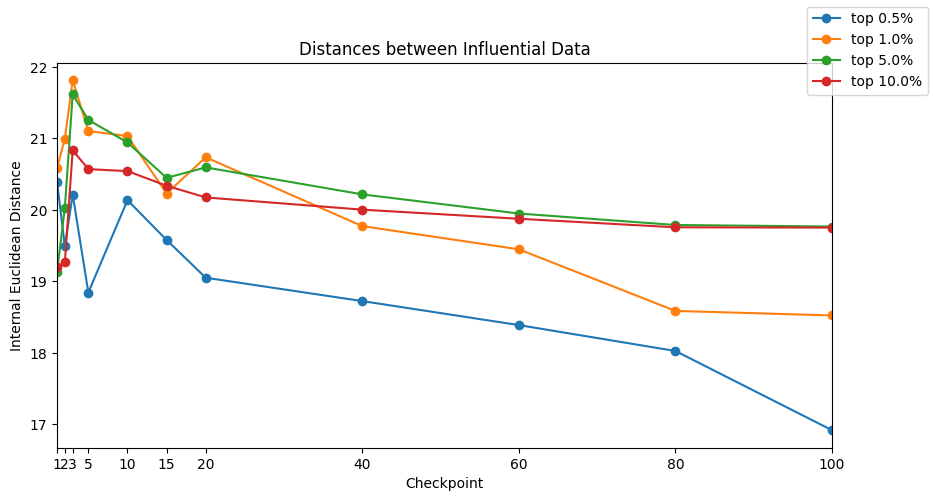

In [39]:
# test selecting 0.5% 1% 5% 10% influential points
num_data = len(embeds_train_dataset)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances between Influential Data")
for p in [0.005, 0.01, 0.05, 0.1]:
    ckpts_embeds = top_last_influences(dogfish_influences, embeds_train_dataset, num_per_row=int(p*num_data))
    inter_distances = []
    for ckpt_embeds in ckpts_embeds:
        ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
        mean_dist = calc_inter_dist(ckpt_embeds)
        inter_distances.append(mean_dist)
    ax1.plot(checkpoint_labels, inter_distances, 'o-', label=f"top {p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
# ax2 = ax1.twinx()
# ax2.set_ylabel("Accuracy")
# ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend()
plt.show()

In [40]:
import random
# Select (1) random 5% training data; (2) last 5% influential data; (3) rest 99% data
def random_p_data(checkpoint_influences, train_dataset, num_data, p=p):
    checkpoints_data = []
    for _ in checkpoint_influences:
        num_select = int(p * num_data)
        random_data = random.sample(list(train_dataset), num_select)
        random_data = [(np.array(data[0]), data[1]) for data in random_data]
        checkpoints_data.append(random_data)
    return checkpoints_data

def rest_data(ckpt_influences, inf_num, train_dataset):
    ckpt_imgs = []
    for _, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=True)
        rest_indexes = sorted_influences[inf_num:]
        top_influential_train_data = [train_dataset[index] for index in rest_indexes]
        imgs = []
        for i, (img, label) in enumerate(top_influential_train_data):
            imgs.append(np.array(img))        
        ckpt_imgs.append(imgs)
    return ckpt_imgs 
# print(random_p_data(dogfish_influences, embeds_train_dataset, num_data=len(embeds_train_dataset), p =0.01)[0].shape)

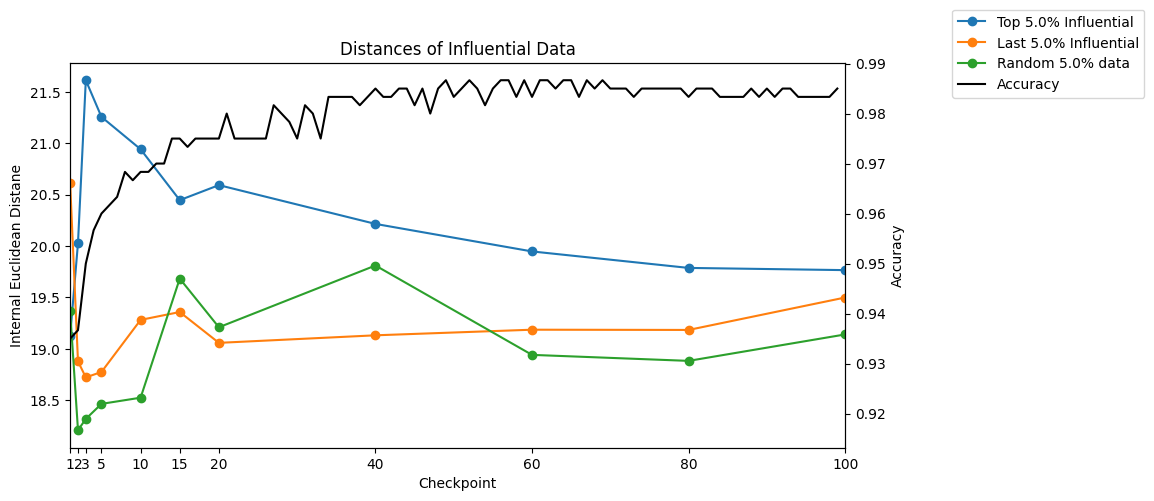

In [41]:
p = 0.05
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

top_ckpts_embeds = top_last_influences(dogfish_influences, embeds_train_dataset, int(p*num_data))
topinf_int_distances = []
for i in range(len(top_ckpts_embeds)):
    # each checkpoint
    embeds = np.array([embed[0] for embed in top_ckpts_embeds[i]])
    repre = calc_inter_dist(embeds)
    topinf_int_distances.append(repre)
ax1.plot(checkpoint_labels, topinf_int_distances, 'o-', label=f"Top {p*100}% Influential")

last_ckpts_embeds = top_last_influences(dogfish_influences, embeds_train_dataset, int(p*num_data), False)
lastinf_int_distances = []
for i in range(len(last_ckpts_embeds)):
    # each checkpoint
    embeds = np.array([embed[0] for embed in last_ckpts_embeds[i]])
    repre = calc_inter_dist(embeds)
    lastinf_int_distances.append(repre)
ax1.plot(checkpoint_labels, lastinf_int_distances, 'o-', label=f"Last {p*100}% Influential")

rand_ckpts_embeds = random_p_data(dogfish_influences, embeds_train_dataset, num_data, p)
rand_int_distances = []
for i in range(len(checkpoints)):
    embeds = np.array([embed[0] for embed in rand_ckpts_embeds[i]])
    repre = calc_inter_dist(embeds)
    rand_int_distances.append(repre)
ax1.plot(checkpoint_labels, rand_int_distances, 'o-', label=f"Random {p*100}% data")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distane")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.title("Distances of Influential Data")
plt.show()

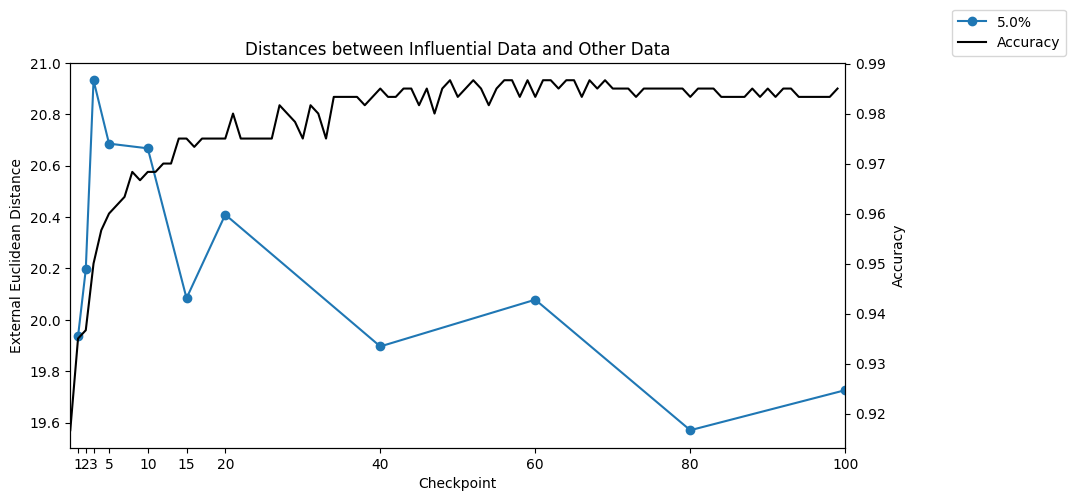

In [42]:
# Euclidean distance from influential points to other points

x_vals =  np.arange(len(checkpoints))
random_embeds = random_p_data(dogfish_influences, embeds_train_dataset, num_data, p)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances between Influential Data and Other Data")
distances = []
for i, ckpt_embeds in enumerate(top_ckpts_embeds):
    inf_embeds = np.array([embed[0] for embed in ckpt_embeds])
    rand_embeds = np.array([embed[0] for embed in random_embeds[i]])
    mean_dist = calc_external_dist(inf_embeds, rand_embeds)
    distances.append(mean_dist)
accuracies = torch.load("../influences/dogfish/dogfish_accuracies.pt")
ax1.plot(checkpoint_labels, distances, 'o-', label=f"{p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("External Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Z_imgs: (90, 8), volume: 809146777600.0
Z_imgs: (90, 8), volume: 1172228145152.0
Z_imgs: (90, 8), volume: 1079106666496.0
Z_imgs: (90, 8), volume: 1003874091008.0
Z_imgs: (90, 8), volume: 616177991680.0
Z_imgs: (90, 8), volume: 520534261760.0
Z_imgs: (90, 8), volume: 516977917952.0
Z_imgs: (90, 8), volume: 420609982464.0
Z_imgs: (90, 8), volume: 368962502656.0
Z_imgs: (90, 8), volume: 337684561920.0
Z_imgs: (90, 8), volume: 357201248256.0


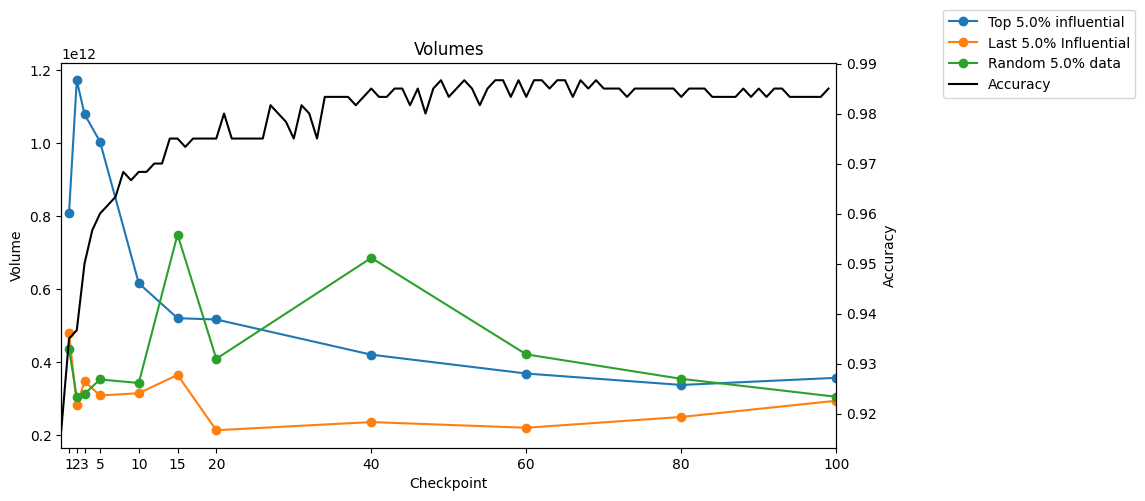

In [43]:
# 0.2 not increase yet; 0.23 ready to increase; 0.252 sharp increase; 0.4 oscillitate, 0.8, 1.0 no change; 0.6 oscillitate; 

from sklearn.decomposition import PCA

def volume(images):
    return np.sqrt(np.linalg.det(images.T@images))

def pca(x, k):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=k)
    pca.fit(x_std)
    return pca.components_

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

topinf_volumes = []
for ckpt_embeds in top_ckpts_embeds:
    # print(ckpt_imgs[0][0].shape)
    ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
    W = pca(ckpt_embeds, 8)
    Z_imgs = ckpt_embeds @ W.T
    print(f"Z_imgs: {Z_imgs.shape}, volume: {volume(Z_imgs)}")
    # print(f"checkpoint: {ckpt_imgs.shape}")
    topinf_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, topinf_volumes, 'o-', label=f"Top {p*100}% influential")

    
lastinf_volumes = []
for ckpt_embeds in last_ckpts_embeds:
    ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
    W = pca(ckpt_embeds, 8)
    Z_imgs = ckpt_embeds @ W.T
    # print(f"checkpoint: {ckpt_imgs.shape}")
    lastinf_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, lastinf_volumes, 'o-', label=f"Last {p*100}% Influential")

rand_volumes = []
for ckpt_embeds in rand_ckpts_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])
    W = pca(embeds, 8)
    Z_imgs = embeds @ W.T
    # print(f"checkpoint: {ckpt_imgs.shape}")
    rand_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, rand_volumes, 'o-', label=f"Random {p*100}% data")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Volume")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.title("Volumes")
plt.show()
# print(len(np.load(DOGFISH_EMB_PATH, mmap_mode='r')["X_train"]))

Top 1% and Last 1% have similar trends but differ a lot in value

For top 1% influential data, volume is larger at later checkpoints; 

**later checkpoints need higher diversity to increase accuracy**

(Checkpoint criterias trends are sensitive to number of top ninfluential data select at each checkpoint)

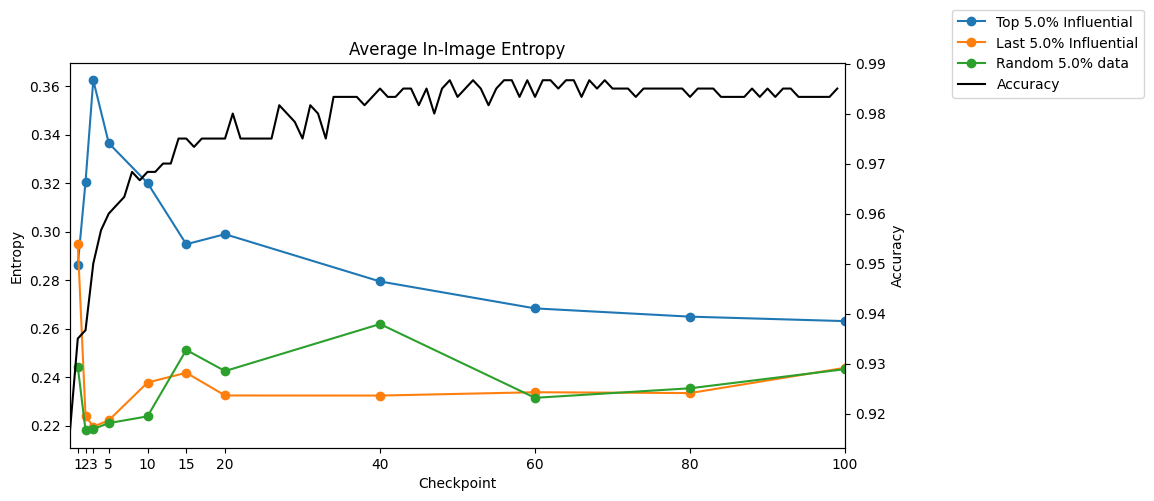

In [44]:
# class balance
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

top_entropies = []
for i in range(len(top_ckpts_embeds)):
    # each checkpoint
    embeds = np.array([img[0] for img in top_ckpts_embeds[i]])
    entropy = calculate_entropy(embeds)
    top_entropies.append(entropy)
ax1.plot(checkpoint_labels, top_entropies, 'o-', label=f"Top {p*100}% Influential")

lastinf_entropies = []
for ckpt_embeds in last_ckpts_embeds:
    ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
    entropy = calculate_entropy(ckpt_embeds)
    lastinf_entropies.append(entropy)
ax1.plot(checkpoint_labels, lastinf_entropies, 'o-', label=f"Last {p*100}% Influential")

rand_entropies = []
for ckpt_embeds in rand_ckpts_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])
    entropy = calculate_entropy(embeds)
    rand_entropies.append(entropy)
ax1.plot(checkpoint_labels, rand_entropies, 'o-', label=f"Random {p*100}% data")

plt.title("Average In-Image Entropy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Entropy")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

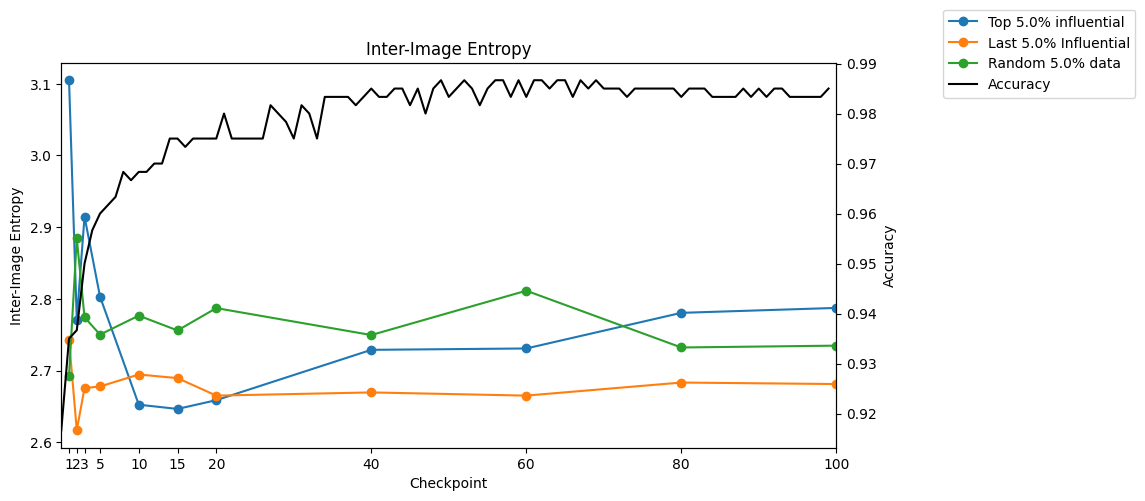

In [45]:
from scipy.spatial.distance import pdist
from scipy.stats import entropy

def image_pairwise_entropy(features):
    pairwise_distances = pdist(features, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=30, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    return entropy(distance_probs)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

topinf_pw_entropies = []
for embeds in top_ckpts_embeds:
    embeds = np.array([img[0] for img in embeds])
    ckpt_entropies = image_pairwise_entropy(embeds)
    topinf_pw_entropies.append(ckpt_entropies)
ax1.plot(checkpoint_labels, topinf_pw_entropies, 'o-', label=f"Top {p*100}% influential")
    
lastinf_pw_entropies = []
for ckpt_embeds in last_ckpts_embeds:
    ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
    pw_entropy = image_pairwise_entropy(ckpt_embeds)
    lastinf_pw_entropies.append(pw_entropy)
ax1.plot(checkpoint_labels, lastinf_pw_entropies, 'o-', label=f"Last {p*100}% Influential")

rand_pw_entropies = []
for ckpt_embeds in rand_ckpts_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])
    pw_entropy = image_pairwise_entropy(embeds)
    rand_pw_entropies.append(pw_entropy)
ax1.plot(checkpoint_labels, rand_pw_entropies, 'o-', label=f"Random {p*100}% data")

plt.title("Inter-Image Entropy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Inter-Image Entropy")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Checkpoint loaded at epoch 1 with completion rate 0.01
Checkpoint loaded at epoch 2 with completion rate 0.02
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
Checkpoint loaded at epoch 1 with completion rate 0.01
Checkpoint loaded at epoch 2 with completion rate 0.02
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpo

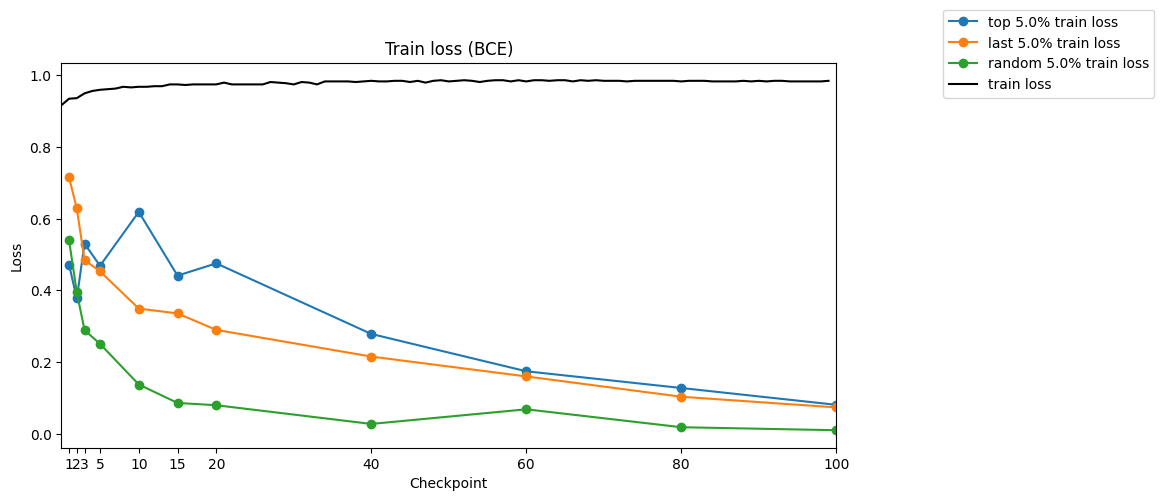

In [47]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, rand_ckpts_embeds]):
    train_losses = [] # BCE loss
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device)
        expect_val = torch.tensor([embed[1] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        optimizer = torch.optim.Adam(V3FC().parameters(), lr=0.0001)
        model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
        loss_fn = nn.BCELoss()
        outputs = model(inputs)
        loss = loss_fn(outputs, expect_val)
        train_losses.append(loss.item())
    ax1.plot(checkpoint_labels, train_losses, 'o-', 
             label=f"{labels[j]} {p*100}% train loss")

plt.title("Train loss (BCE)")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Loss")
ax1.set_xticks(checkpoint_labels)
train_losses = torch.load("../influences/dogfish/dogfish_train_losses.pt")
ax1.plot(accuracies, label="train loss", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Checkpoint loaded at epoch 1 with completion rate 0.01
Checkpoint loaded at epoch 2 with completion rate 0.02
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
Checkpoint loaded at epoch 1 with completion rate 0.01
Checkpoint loaded at epoch 2 with completion rate 0.02
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpo

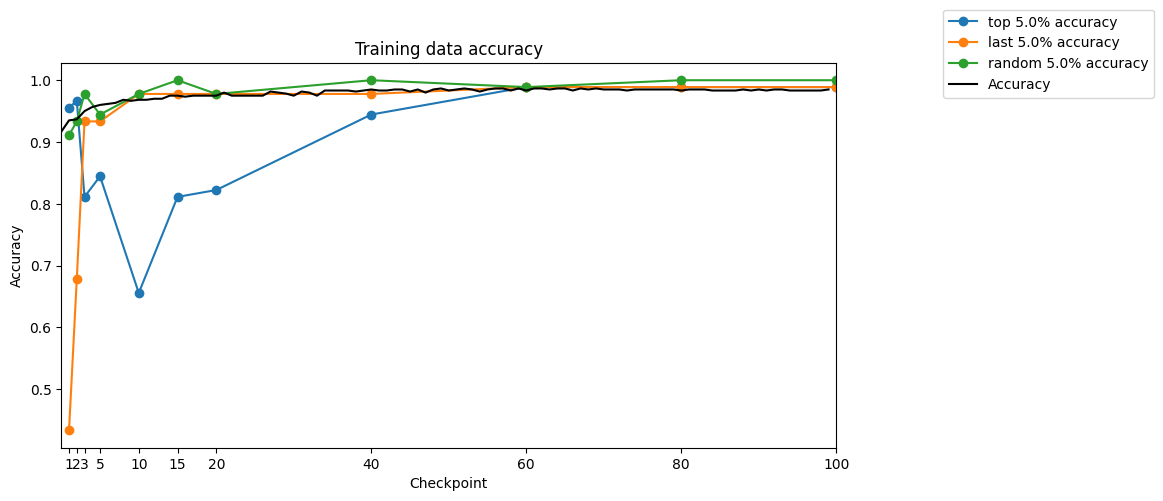

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, rand_ckpts_embeds]):
    accuracies = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device)
        expect_val = torch.tensor([embed[1] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        predictions = (outputs > 0.5).int()
        accuracy = (predictions == expect_val).sum() / len(expect_val)
        accuracies.append(accuracy)
    ax1.plot(checkpoint_labels, accuracies, 'o-', 
             label=f"{labels[j]} {p*100}% accuracy")

plt.title("Training data accuracy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(checkpoint_labels)
accuracies = torch.load("../influences/dogfish/dogfish_accuracies.pt")
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()